# Ghost count: conditional snapshot estimate

Estimate of businesses on the books that would be recorded OOB if visited at the snapshot. Snapshot date August 23, 2026 includes that entire date; the hypothetical visit instant is August 24 at 00:00, and all features use strictly earlier observations.

The headline population requires a positive observation since January 1, 2023 and no unresolved OOB. Full-history identities appear only in the sensitivity section.

In [1]:
import os
from pathlib import Path

root = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(root)
os.environ["OMP_NUM_THREADS"] = "4"
import pandas as pd
from IPython.display import display

from storefronts.gold import pipeline
from storefronts.notebook_tools import finish, style

style()

This notebook asks how many identities in the inspection record would likely be recorded OOB if visited at the end of the data. It is a model-based estimate, not a census, and is only as reliable as the match between the scored population and the visits the model learned from.

## Population and assumptions

Include each business with a storefront observation, a positive observation since January 1, 2023, and no unresolved OOB record at the snapshot. Use the saved calibrated live **history-only** LightGBM model. The planned-type model is not used.

**Assumptions:** The model learned from visited businesses only. Visit selection is not random. Probabilities describe *recorded OOB if visited*, not proof of cessation or a physical property condition. Transport from 2024/2025 visited businesses to recent-positive on-book identities in August 2026 is unvalidated, especially for very old last observations. An identity is a normalized name at a storefront key, subject to splitting, merging and retrospective cross-switch linkage. The expected count is a sum of probabilities under these assumptions, not a registry census.

In [2]:
from pprint import pprint

from storefronts.ghosts import run

pprint(pipeline("ghost_rows"), width=100)
ghost = run(resamples=500)
display(
    pd.DataFrame(
        [
            {
                k: ghost[k]
                for k in ["snapshot_date", "eligible_businesses", "expected_oob", "bootstrap_ci95"]
            }
        ]
    )
)
print(ghost["bootstrap_method"])

[{'$match': {'has_prior_positive': True, 'oob_unresolved': False}}, {'$sort': {'_id': 1}}]


,snapshot_date,eligible_businesses,expected_oob,bootstrap_ci95
0,2026-08-23,43447,5722.235855,"[5443.295313, 5985.745941]"


500 business-cluster resamples of Oct-Dec 2024 calibration rows; refit Platt calibrator only, freeze base model and snapshot population. Calibration uncertainty only; excludes base-model fitting, population selection, stale identities and future drift.


The headline population contains 43,447 identities with a positive observation since 2023 and no unresolved OOB. Their calibrated probabilities sum to 5,722 expected recorded-OOB outcomes if visited, or 13.2%. Restricting to recent positives reduces the distance from the model's fitted population, but does not remove inspection-selection bias or identity error. The broader historical population is retained only as a sensitivity below.

## Industry and NTA estimates

Every group reports its denominator. These estimates inherit inspection selection, identity and model transport assumptions. NTA is the latest recorded location; no claim about neighborhood property conditions is made. Industry and NTA estimates use the headline positive-since-2023 population.

,industry_group,businesses,expected_oob,mean_probability
0,general_retail,13098,1996.639949,0.152439
1,personal_services,9361,1468.965525,0.156924
2,food_grocery,8695,840.303345,0.096642
3,tobacco_vape_cannabis,6247,795.988244,0.127419
4,secondhand_pawn,2292,285.024688,0.124356
5,auto_fuel_parking,2709,189.514569,0.069957
6,lodging,747,98.456873,0.131803
7,other,199,32.885056,0.165252
8,wholesale_industrial,67,9.393933,0.140208
9,entertainment,22,2.994319,0.136105


,nta2020,nta_name,businesses,expected_oob,mean_probability
0,MN0502,Midtown-Times Square,1116,145.512242,0.130387
1,MN0501,Midtown South-Flatiron-Union Square,646,91.515508,0.141665
2,QN0707,Flushing-Willets Point,682,86.021402,0.126131
3,QN1201,Jamaica,680,84.923598,0.124888
4,MN0201,SoHo-Little Italy-Hudson Square,650,82.664969,0.127177
...,...,...,...,...,...
212,QN0572,Middle Village Cemetery,1,0.092653,0.092653
213,QN0171,St. Michael's Cemetery,1,0.079325,0.079325
214,MN6491,Central Park,1,0.074195,0.074195
215,BK1891,Marine Park-Plumb Island,1,0.060757,0.060757


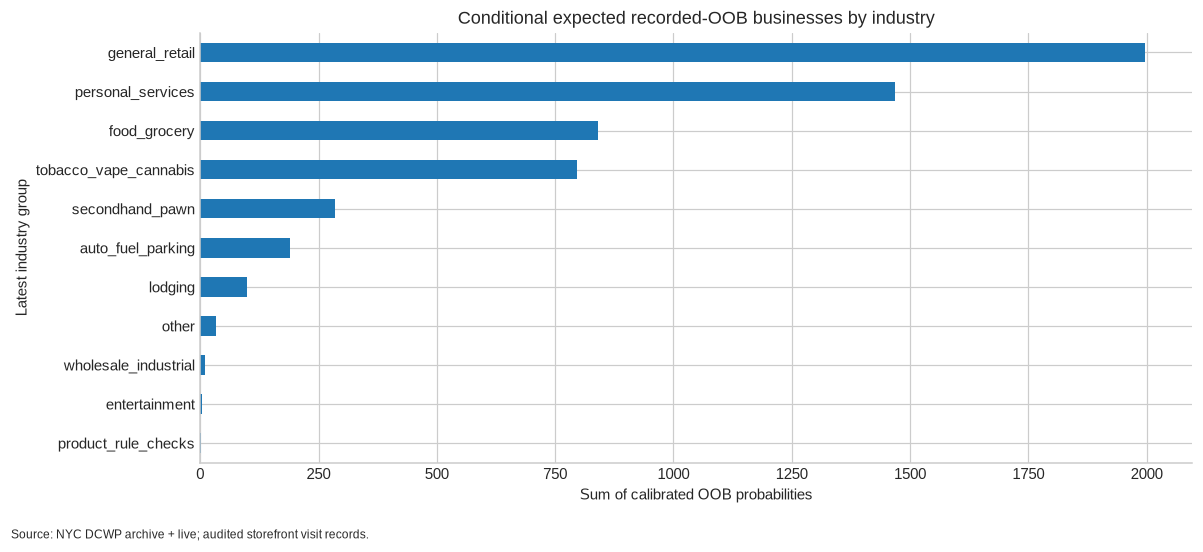

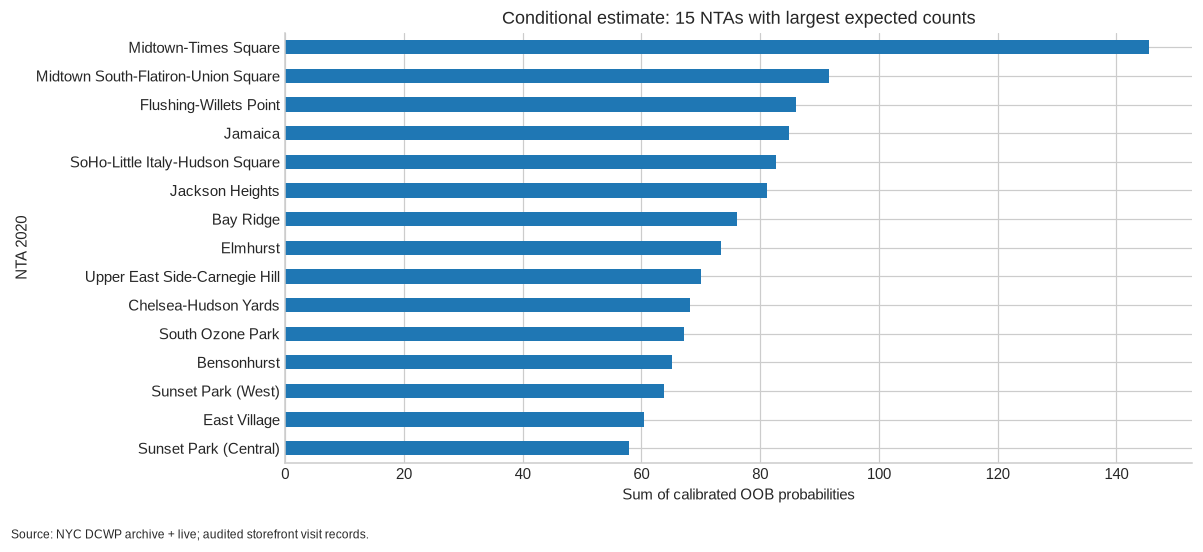

In [3]:
industry = pd.DataFrame(ghost["by_industry"])
nta = pd.DataFrame(ghost["by_nta"])
display(industry)
display(nta)
ax = industry.sort_values("expected_oob").plot.barh(
    x="industry_group", y="expected_oob", legend=False
)
finish(
    ax,
    "Conditional expected recorded-OOB businesses by industry",
    "Sum of calibrated OOB probabilities",
    "Latest industry group",
)
ax = (
    nta.head(15).sort_values("expected_oob").plot.barh(x="nta_name", y="expected_oob", legend=False)
)
finish(
    ax,
    "Conditional estimate: 15 NTAs with largest expected counts",
    "Sum of calibrated OOB probabilities",
    "NTA 2020",
)

General retail and personal services carry the largest expected counts, at 1,997 and 1,469, with 13,098 and 9,361 identities. Their size contributes substantially to those totals. Tobacco, vape and cannabis has a mean probability of 12.7%; food and grocery is lower at 9.7%, and auto, fuel and parking is lowest among groups with at least 1,000 identities, at 7.0%. These comparisons do not establish an effect of inspection frequency. Midtown-Times Square leads the NTA expected counts. The 199 recent-positive identities without an NTA are excluded from the map but retained in headline totals.

## Full-history sensitivity and uncertainty

The positive-since-2023 estimate is primary. The full-history sensitivity additionally includes identities whose last positive predates 2023. The by-last-positive-year table and diagnostics below use that full-history population. The no-chain sensitivity refits the same LightGBM protocol without the chain flag, with a separate validation-only calibrator; it does not remove chain businesses. The no-chain and raw-versus-calibrated variants use the primary recent-positive population. The raw-versus-calibrated comparison holds population and base model fixed.

The interval resamples business clusters in the calibration slice and refits the Platt calibrator 500 times while holding the base model and snapshot population fixed. It covers calibration-sample uncertainty only. It is not a confidence interval for actual cessation; selection bias, model-fit uncertainty, identity error and temporal drift are not covered.

In [4]:
sensitivity = pd.DataFrame(ghost["sensitivities"])
display(sensitivity)
age = pd.DataFrame(ghost["full_history_by_last_positive_year"])
display(age)

,variant,businesses,expected_oob
0,positive_since_2023_primary,43447,5722.235855
1,positive_since_2023_uncalibrated,43447,4771.692885
2,full_history_calibrated_sensitivity,132188,50732.420366
3,positive_since_2023_refit_without_chain_flag,43447,5778.316099


,last_positive_year,businesses,expected_oob,mean_probability
0,2011,11995,6168.193561,0.514230
1,2013,11163,5700.848452,0.510691
2,2012,10869,5576.191868,0.513036
3,2010,9641,4990.290516,0.517611
4,2014,8905,4553.194242,0.511308
5,2017,6527,3761.627249,0.576318
6,2018,5244,2979.025193,0.568083
7,2015,5863,2942.384416,0.501856
8,2016,5916,2898.651202,0.489968
9,2019,5332,2706.330442,0.507564


For identities last seen positive in 2010–2019, annual mean predicted probabilities are
about **0.50–0.58** (actual range **0.490–0.576**; the 2016 mean is 0.490). The model was
fitted only on visits the agency chose to make. The full-history total therefore depends
on extrapolation outside the fitted visited population; it is retained as a sensitivity.

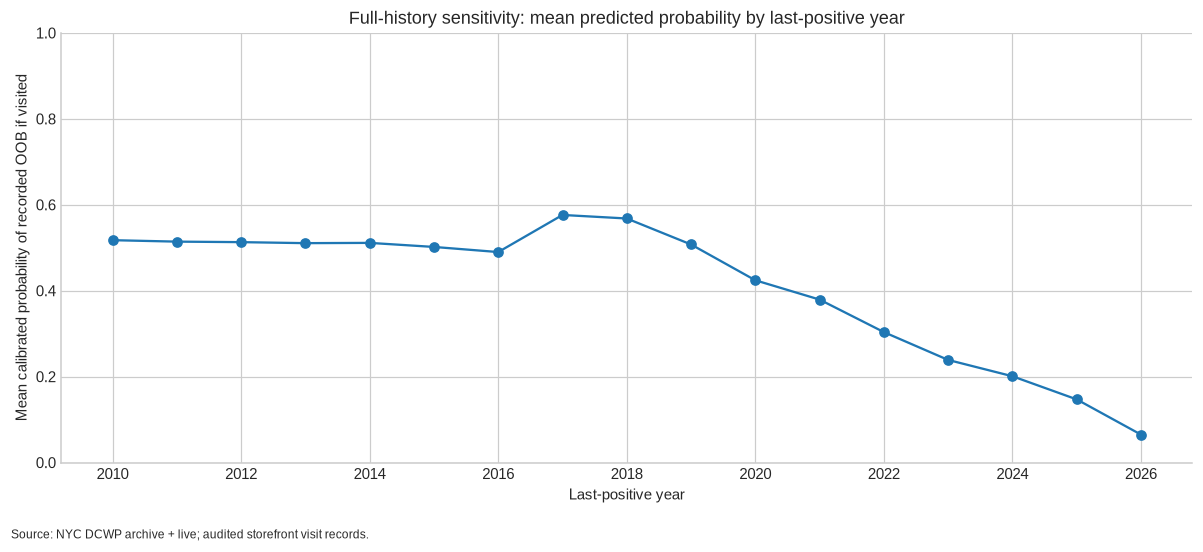

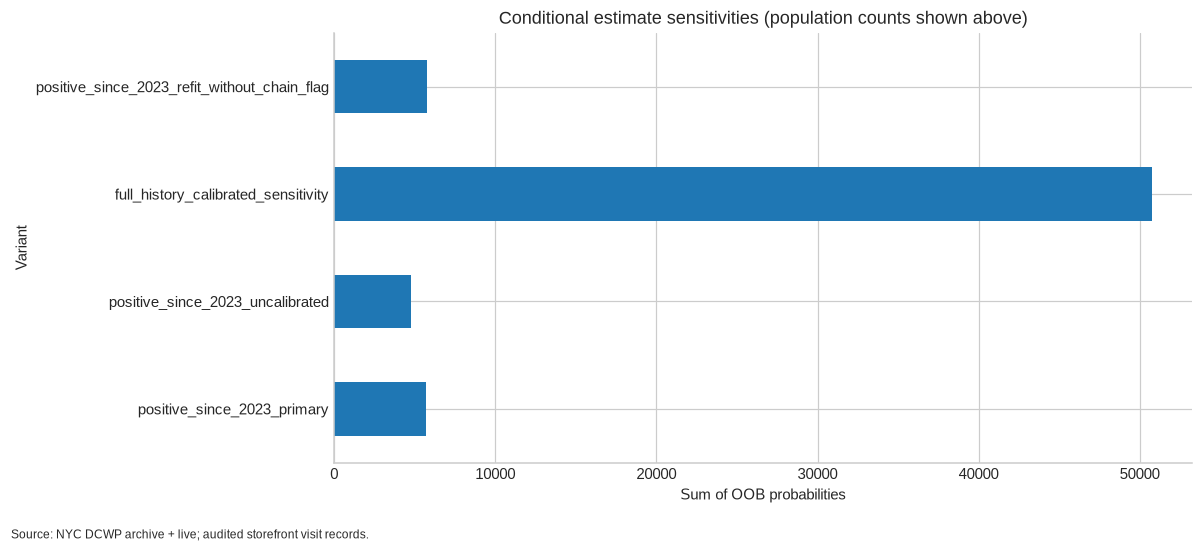

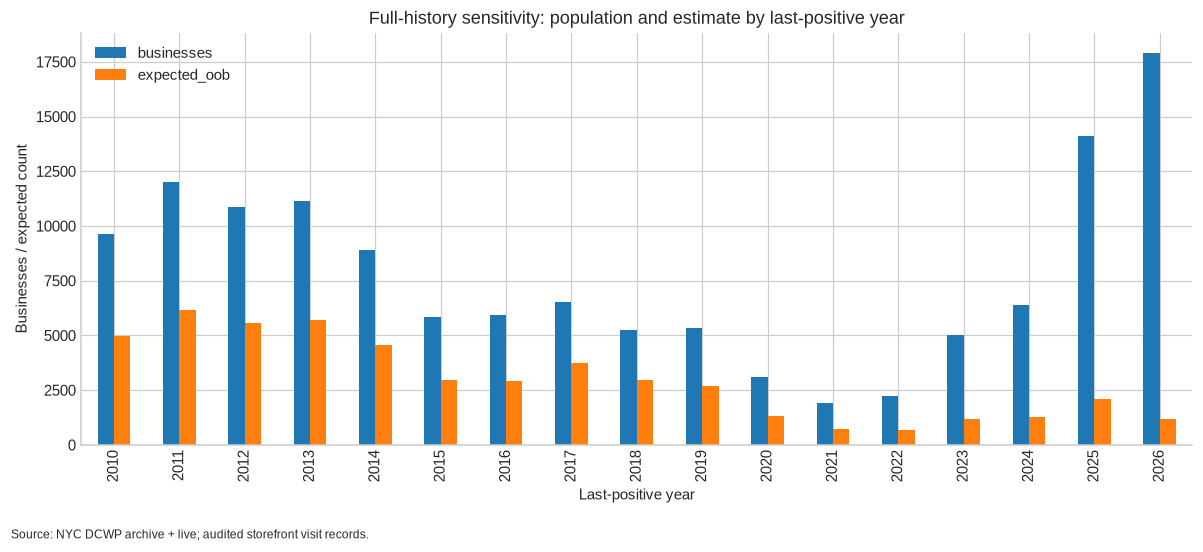

In [5]:
ax = age.sort_values("last_positive_year").plot(
    x="last_positive_year", y="mean_probability", marker="o", legend=False
)
ax.set_ylim(0, 1)
finish(
    ax,
    "Full-history sensitivity: mean predicted probability by last-positive year",
    "Last-positive year",
    "Mean calibrated probability of recorded OOB if visited",
)
ax = sensitivity.plot.barh(x="variant", y="expected_oob", legend=False)
finish(
    ax,
    "Conditional estimate sensitivities (population counts shown above)",
    "Sum of OOB probabilities",
    "Variant",
)
ax = age.sort_values("last_positive_year").plot.bar(
    x="last_positive_year", y=["businesses", "expected_oob"]
)
finish(
    ax,
    "Full-history sensitivity: population and estimate by last-positive year",
    "Last-positive year",
    "Businesses / expected count",
)

Calibration raises the recent-positive estimate from 4,772 to 5,722, or 19.9%; removing the chain flag gives 5,778, about 1.0% above the headline. Population choice changes more: the full-history sensitivity sums to 50,732 across 132,188 identities; restricting to recent positives cuts it by 88.7%. Full-history annual means for identities last positive in 2010 to 2019 range from 0.490 to 0.576, despite seven to sixteen years without a positive. The model learned only from visits the agency chose to make. Long-stale identities that are still visited may differ from those never revisited, so the full-history total depends on extrapolation outside the fitted population. For recent identities, probabilities rise with staleness, from 6.5% for a last positive in 2026 to 23.9% for 2023.